# Fit an MLP mixture-density model and compare it to the HMM (Metric A)

A **Mixture Density Network (MDN)**: a feed-forward MLP predicts a 3-component
mixture over the **same emission family** as `fit_hmm.py`
(F = Normal(0, σ), L = Gamma(−dθ), R = Gamma(+dθ)), from an autoregressive
history of previous `dtheta` **plus** the stimulus term `b = sin(bearing-to-dots)`.
It replaces the HMM's latent-state prior with a direct feedforward function of
(recent history + stimulus), but exposes the *same* one-step predictive density
`log p(dtheta_t | features_t)`, so it drops straight into the evaluation pipeline.

- **MLP-basic** (3 outputs) — MLP → F/L/R mixture weights; σ, α, θ are global
  learnable scalars, symmetric gammas.
- **MLP-full** (8 outputs) — MLP → 3 weights + per-bout `[σ_F, α_L, θ_L, α_R, θ_R]`
  (F mean fixed at 0), asymmetric gammas. Heteroscedastic.

The payoff is Section 5: **does the MLP beat the HMM in held-out density bits/bout?**
The batch equivalent is `scripts/fit_MLP.py`.

## 1. Setup & load per-fish records

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, gamma as gamma_dist

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import fit_MLP as M, evaluate as E, fit_hmm as H   # notebook & CLI share code

df = E.load_bouts(str(ROOT / "data" / "bouts_GsizeMotionSingle.csv"))
records = E.build_records(df, min_len=10)
recs = list(records.values())
ctx = E.make_context(recs, cfg={})               # dt/dist pools for sampling
print(f"{len(recs)} fish, {sum(r.n for r in recs)} bouts")

# feature sanity: K=5 dtheta history + 1 stimulus (b) -> D=6
cfg_feat = dict(K=5, stim_mode="simple", include_symbols=False,
                dth_scale=float(np.std(np.concatenate([r.dtheta for r in recs]))),
                rich_scales=None)
Xs, ys = M.build_feature_sequences(recs, cfg_feat)
print("feature matrix:", Xs.shape, "  (5 history + 1 stimulus)")

15 fish, 70590 bouts
feature matrix: (70590, 6)   (5 history + 1 stimulus)


## 2. MLP-basic — 3 outputs (F/L/R weights; global symmetric emission)
The MLP outputs only the mixture weights; σ, α, θ are shared scalars fit jointly
(exactly the HMM's emission family, but the mixing is a feedforward function of
history+stimulus instead of a Markov recursion).

basic: final val NLL 5.4394 | features D = 6


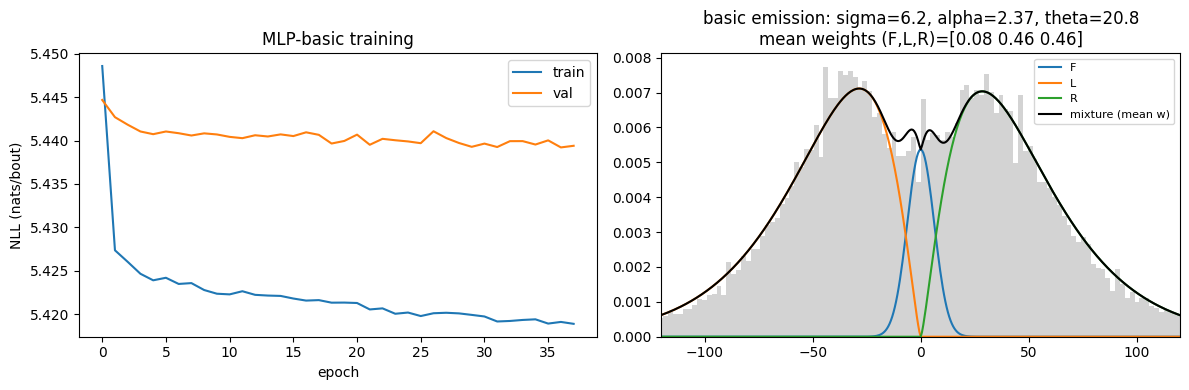

In [2]:
m_basic = M.MLPDensity(mode="basic", K=5, stim_mode="simple", hidden=64, epochs=80, seed=0)
m_basic.fit(recs, ctx)
print("basic: final val NLL", round(m_basic.history["val"][-1], 4),
      "| features D =", m_basic.config["n_features"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(m_basic.history["train"], label="train"); ax[0].plot(m_basic.history["val"], label="val")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("NLL (nats/bout)"); ax[0].legend()
ax[0].set_title("MLP-basic training")

# emission overlay: global scalar params + MEAN predicted weights over all bouts
alld = np.concatenate([r.dtheta for r in recs])
wall = np.concatenate([M.predict_params(m_basic._model, M.build_feature_matrix(r, m_basic._cfg_feat))[0]
                       for r in recs], axis=0)
wm = wall.mean(0)
_, sF, aL, tL, _, _ = M.predict_params(m_basic._model, M.build_feature_matrix(recs[0], m_basic._cfg_feat))
sigma, alpha, theta = sF[0], aL[0], tL[0]
xg = np.linspace(-180, 180, 601)
pdf_f = wm[0] * norm.pdf(xg, 0, sigma)
pdf_l = np.where(xg < 0, wm[1] * gamma_dist.pdf(-xg, alpha, scale=theta), 0.0)
pdf_r = np.where(xg > 0, wm[2] * gamma_dist.pdf(xg, alpha, scale=theta), 0.0)
ax[1].hist(alld, bins=160, range=(-180, 180), density=True, color="lightgray")
ax[1].plot(xg, pdf_f, label="F"); ax[1].plot(xg, pdf_l, label="L"); ax[1].plot(xg, pdf_r, label="R")
ax[1].plot(xg, pdf_f + pdf_l + pdf_r, "k", lw=1.5, label="mixture (mean w)")
ax[1].set_xlim(-120, 120); ax[1].legend(fontsize=8)
ax[1].set_title(f"basic emission: sigma={sigma:.1f}, alpha={alpha:.2f}, theta={theta:.1f}\nmean weights (F,L,R)={wm.round(2)}")
plt.tight_layout(); plt.show()

## 3. MLP-full — 8 outputs (per-bout asymmetric params)
Now the MLP predicts, **per bout**, 3 weights + `[σ_F, α_L, θ_L, α_R, θ_R]`
(forward mean fixed at 0; gammas asymmetric). This is a heteroscedastic MDN: the
shape of the predictive density adapts to the recent history and stimulus.
*(The full head needs more epochs than basic to calibrate — the per-bout params
are freer, so give it enough training.)*

full: final val NLL 5.4063


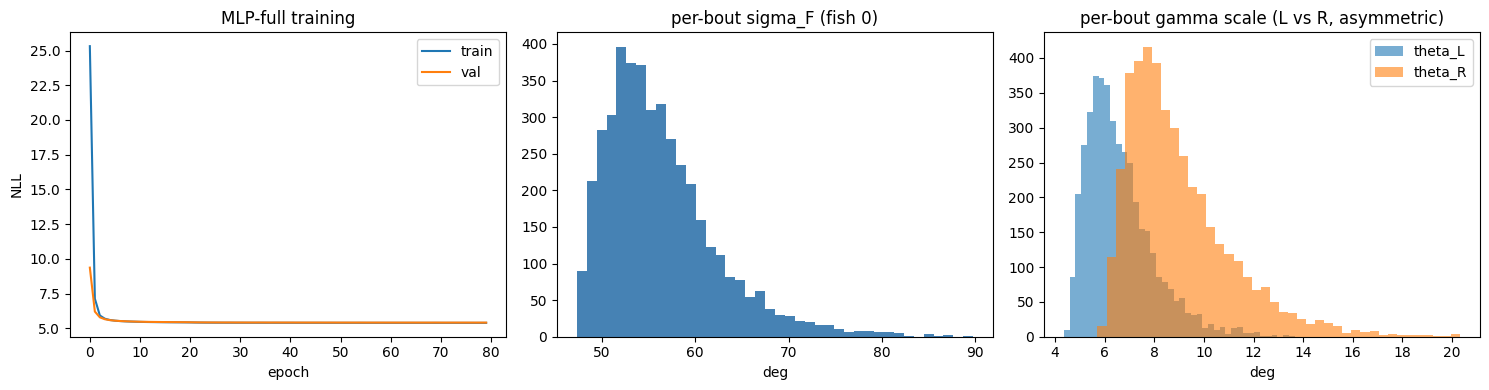

mean weights (F,L,R): [0.704 0.161 0.135]


In [3]:
m_full = M.MLPDensity(mode="full", K=5, stim_mode="simple", hidden=64, epochs=80, seed=0)
m_full.fit(recs, ctx)
print("full: final val NLL", round(m_full.history["val"][-1], 4))

# per-bout parameter variation on one fish (heteroscedasticity)
r = recs[0]
w, sF, aL, tL, aR, tR = M.predict_params(m_full._model, M.build_feature_matrix(r, m_full._cfg_feat))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(m_full.history["train"], label="train"); ax[0].plot(m_full.history["val"], label="val")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("NLL"); ax[0].legend(); ax[0].set_title("MLP-full training")
ax[1].hist(sF, bins=40, color="steelblue"); ax[1].set_xlabel("deg")
ax[1].set_title(f"per-bout sigma_F (fish {r.fish_id})")
ax[2].hist(tL, bins=40, alpha=0.6, label="theta_L"); ax[2].hist(tR, bins=40, alpha=0.6, label="theta_R")
ax[2].set_xlabel("deg"); ax[2].legend(); ax[2].set_title("per-bout gamma scale (L vs R, asymmetric)")
plt.tight_layout(); plt.show()
print("mean weights (F,L,R):", w.mean(0).round(3))

## 4. Generate synthetic trajectories (autoregressive) and compare
`sample` free-runs the MLP: each bout's `dtheta` is drawn from the predicted
mixture, then fed back as history; the stimulus is teacher-forced from the real
fish. `dt`/`distance` are resampled from empirical pools (as in the HMM).

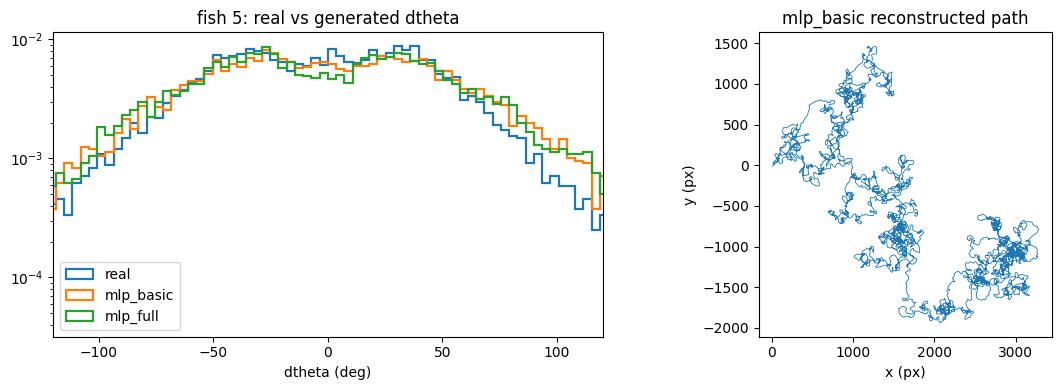

In [4]:
rng = np.random.default_rng(1)
r = records[5]
gen_b = m_basic.sample(r, rng)
gen_f = m_full.sample(r, rng)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for lab, d in [("real", r.dtheta), ("mlp_basic", gen_b["dtheta"]), ("mlp_full", gen_f["dtheta"])]:
    ax[0].hist(d, bins=100, range=(-180, 180), density=True, histtype="step", lw=1.6, label=lab)
ax[0].set_yscale("log"); ax[0].set_xlim(-120, 120); ax[0].set_xlabel("dtheta (deg)")
ax[0].legend(); ax[0].set_title(f"fish {r.fish_id}: real vs generated dtheta")
x, y, _ = H.reconstruct_xy(gen_b["dtheta"], gen_b["distance_px"])
ax[1].plot(x, y, lw=0.6); ax[1].set_aspect("equal")
ax[1].set_xlabel("x (px)"); ax[1].set_ylabel("y (px)"); ax[1].set_title("mlp_basic reconstructed path")
plt.tight_layout(); plt.show()

## 5. Evaluation — does the MLP beat the HMM? (Metric A)
Leave-3-fish-out CV of held-out **density bits/bout** (lower = better). We drop the
two MLPs into the same `model_factories` list as the HMMs/baselines and run the
identical pipeline — so `mlp_basic`/`mlp_full` are ranked next to `spontaneous`,
`simple_stim`, `marginal_density`. `cfg=dict(mlp_epochs=40)` caps the per-fold
training (10 MLP fits total); raise it for final numbers.

  fold 0: trained on 12 fish, scored [2, 4, 6]
  fold 1: trained on 12 fish, scored [7, 9, 11]
  fold 2: trained on 12 fish, scored [3, 5, 13]
  fold 3: trained on 12 fish, scored [8, 10, 14]
  fold 4: trained on 12 fish, scored [0, 1, 12]


,model,metric,mean,mean_lo,mean_hi,median,n_fish
3,mlp_full,bits_per_bout,7.8150,7.7251,7.9262,7.7949,15
2,mlp_basic,bits_per_bout,7.8529,7.7554,7.9779,7.8161,15
4,simple_stim,bits_per_bout,7.8576,7.7630,7.9797,7.8127,15
5,spontaneous,bits_per_bout,7.8743,7.7798,7.9945,7.8318,15
1,marginal_density,bits_per_bout,7.8877,7.7908,8.0094,7.8543,15
0,bigram,bits_per_bout,NaN,NaN,NaN,NaN,0
6,unigram,bits_per_bout,NaN,NaN,NaN,NaN,0


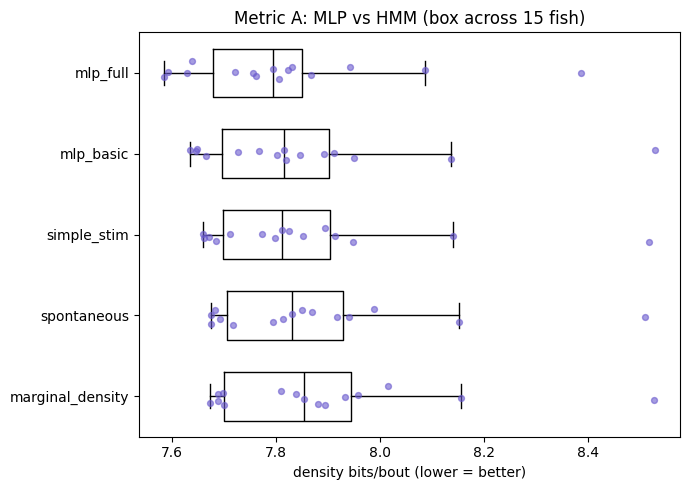

Paired per-fish comparison (higher nats/bout = better):


{'model_a': 'mlp_full',
 'model_b': 'simple_stim',
 'metric': 'nats_per_bout',
 'n_fish': 15,
 'prefer_a': 14,
 'prefer_b': 1,
 'ties': 0,
 'median_delta': 0.03263035887550991,
 'delta_lo': 0.013007734963666806,
 'delta_hi': 0.0386855280501095,
 'wilcoxon_p': 0.00152587890625,
 'sign_test_p': 0.0009765625}

{'model_a': 'mlp_basic',
 'model_b': 'spontaneous',
 'metric': 'nats_per_bout',
 'n_fish': 15,
 'prefer_a': 13,
 'prefer_b': 2,
 'ties': 0,
 'median_delta': 0.017570801819005055,
 'delta_lo': 0.007812114513868984,
 'delta_hi': 0.021282605297852975,
 'wilcoxon_p': 0.00115966796875,
 'sign_test_p': 0.00738525390625}

In [5]:
folds = E.make_folds(sorted(records), n_folds=5, seed=0)
facs = E.default_model_factories(restarts=1, max_iter=120) + [
    lambda: M.MLPDensity(mode="basic", K=5, stim_mode="simple", hidden=64),
    lambda: M.MLPDensity(mode="full",  K=5, stim_mode="simple", hidden=64)]
likA = E.add_skill_scores(E.cross_validate_likelihood(records, facs, folds,
                                                      cfg=dict(mlp_epochs=40), verbose=True))
sumA = E.summarize(likA, metric="bits_per_bout")
display(sumA.round(4))

order = sumA.dropna(subset=["mean"]).sort_values("mean")["model"].tolist()
data = [likA.loc[likA.model == m, "bits_per_bout"].dropna().to_numpy() for m in order]
fig, ax = plt.subplots(figsize=(7, 0.7 * len(order) + 1.5))
ax.boxplot(data, vert=False, showfliers=False, widths=0.6, medianprops=dict(color="black"))
rng = np.random.default_rng(0)
for i, dv in enumerate(data):
    ax.scatter(dv, rng.normal(i + 1, 0.06, len(dv)), s=18, color="slateblue", alpha=0.6, zorder=3)
ax.set_yticks(range(1, len(order) + 1)); ax.set_yticklabels(order)
ax.set_xlabel("density bits/bout (lower = better)")
ax.set_title("Metric A: MLP vs HMM (box across 15 fish)"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

print("Paired per-fish comparison (higher nats/bout = better):")
display(E.paired_compare(likA, "mlp_full", "simple_stim", "nats_per_bout", higher_better=True))
display(E.paired_compare(likA, "mlp_basic", "spontaneous", "nats_per_bout", higher_better=True))

## Notes & next steps
- **Reading it:** lower `bits_per_bout` wins; `paired_compare` gives the per-fish
  sign test (prefer ≥13/15 agreement before declaring a winner). Also check the
  stimulus-present stratum (`nats_stim`) — the MLP should earn its keep where dots move.
- **Inputs are a config knob:** `K` (history length), `stim_mode ∈ {none, simple, rich}`,
  `include_symbols`. `rich` needs `abs_dict.pkl` (build records with `abs_dict`/`roi`).
- **MLP-full needs enough epochs** (its per-bout params are freer); under-training
  can inflate held-out bits/bout. Raise `mlp_epochs`/`hidden` for final numbers.
- **Next:** deeper nets, a GRU/attention history encoder, or the rich stimulus
  features — all slot into the same `MLPDensity` adapter and the same Metric A/B pipeline.